In [34]:
import numpy as np
from matplotlib import pyplot as plt
from hw3code import lattice_eigensolution as LE
from hw3code import b

In [46]:
Z = 500

Xpath = np.linspace(-b,b,2*Z)
Xpoints = [Xpath[0],Xpath[Z-1],Xpath[-1]]
Knames = [r'$-X$',r'$\Gamma$',r'$X$']

In [47]:

N_odd1 = 13
N_even1 = N_odd1+1

Eodd1,Codd1 = LE(N_odd1,Z)
Eeven1,Ceven1 = LE(N_even1,Z)


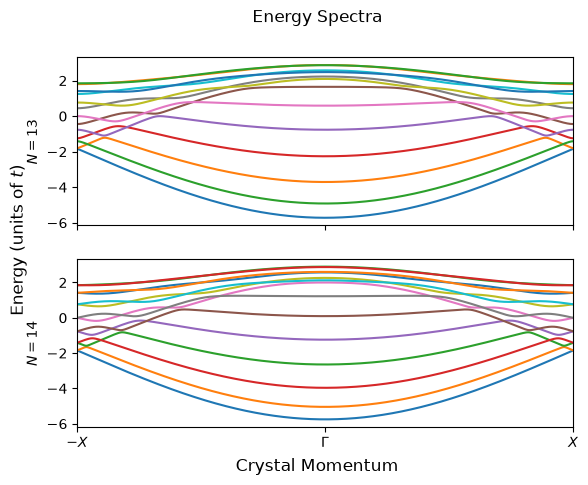

In [48]:
#Plotting

fig, (ax1,ax2) = plt.subplots(2)
for E in Eodd1:
    ax1.plot(Xpath,E)

ax1.set_ylabel(f'$N={N_odd1}$');
ax1.set_xlim(Xpoints[0],Xpoints[-1])
ax1.set_xticks(Xpoints,Knames);


for E in Eeven1:
    ax2.plot(Xpath,E)
ax2.sharex(ax1)
ax2.set_ylabel(f'$N={N_even1}$');


ax1.tick_params(labelbottom = False)
fig.suptitle('Energy Spectra');
fig.supylabel(r'Energy (units of $t$)');
fig.supxlabel('Crystal Momentum');

Text(0.5, 1.0, 'Even Lattice')

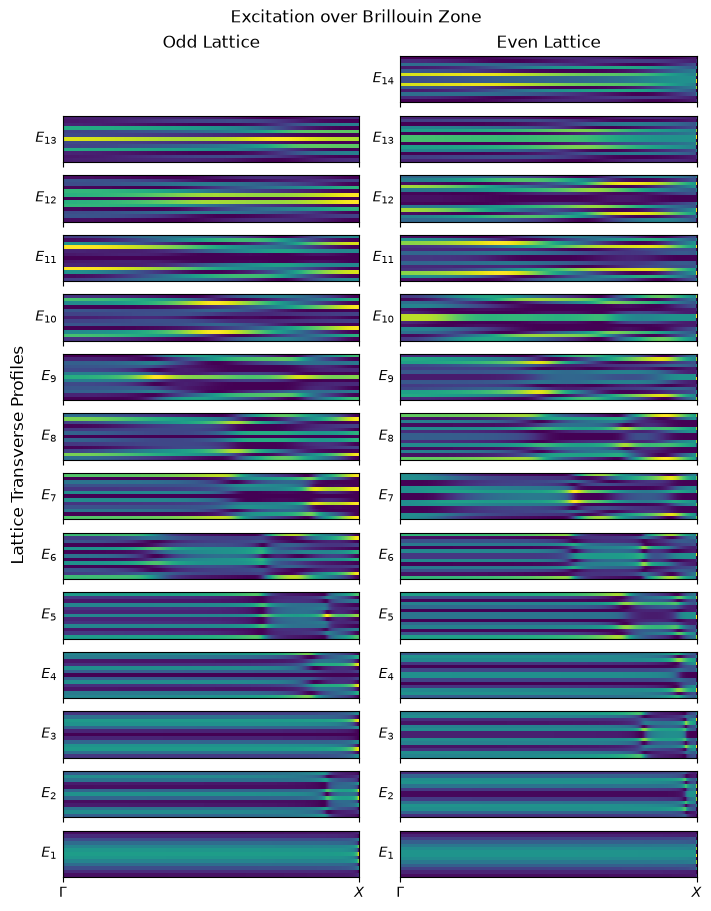

In [97]:
fig, axes = plt.subplots(N_even1,2, sharex = True, figsize = (7,9), constrained_layout = True)

Xmesheven, Ymesheven = np.meshgrid(Xpath[Z:],np.arange(N_even1))
Xmeshodd, Ymeshodd = np.meshgrid(Xpath[Z:],np.arange(N_odd1))

for col,Xmesh,Ymesh,C in zip(axes.T,[Xmeshodd,Xmesheven],[Ymeshodd,Ymesheven],[Codd1,Ceven1]):
        for i,ax in enumerate(reversed(col)):
                try:
                        P = abs(C[i,Z:,:].T)**2
                        ax.pcolormesh(Xmesh,Ymesh, P, cmap = 'viridis')
                        ax.set_yticks([])
                        ax.set_ylabel(rf'$E_{{{i+1}}}$', rotation = 0, ha= 'right', va = 'center')
                except:
                        ax.set_axis_off()
axes[0][-1].set_xticks([Xpath[Z-1],Xpath[2*Z-1]],[r'$\Gamma$',r'$X$'])
axes[0][-1].set_xlim(Xpath[Z-1],Xpath[2*Z-1]);


fig.supylabel('Lattice Transverse Profiles');
fig.suptitle('Excitation over Brillouin Zone');
axes[0][0].set_title('Odd Lattice')
axes[0][1].set_title('Even Lattice')

In [18]:
N_odd2 = 199
N_even2 = N_odd2+1

Eodd2,Codd2 = LE(N_odd2,Z)
Eeven2,Ceven2 = LE(N_even2,Z)

In [21]:
PoddX = Codd2[-1]**2
PoddGamma = Codd2[:,Z-1]**2
PoddHalf = Codd2[:,3*Z//4 - 1]**2

PevenX = Ceven2[-1]**2
PevenGamma = Ceven2[:,Z-1]**2
PevenHalf = Ceven2[:,3*Z//4 - 1]**2

In [28]:
Ceven1

array([[[ 0.05788414+0.j,  0.36721387+0.j,  0.59973806+0.j, ...,
         -0.59591167-0.j,  0.37168361+0.j, -0.00692062-0.j],
        [ 0.26164594+0.j, -0.2641266 -0.j,  0.42331234+0.j, ...,
          0.42731835+0.j,  0.26409583+0.j, -0.26161582-0.j],
        [ 0.26046563+0.j, -0.26543133-0.j,  0.421284  +0.j, ...,
          0.42928519+0.j,  0.26530691+0.j,  0.26034636+0.j],
        ...,
        [ 0.26046563+0.j, -0.26543133-0.j,  0.421284  +0.j, ...,
          0.42928519+0.j,  0.26530691+0.j,  0.26034636+0.j],
        [ 0.26164594+0.j, -0.2641266 -0.j,  0.42331234+0.j, ...,
          0.42731835+0.j,  0.26409583+0.j, -0.26161582-0.j],
        [ 0.05788414+0.j,  0.36721387+0.j,  0.59973806+0.j, ...,
         -0.59591167-0.j,  0.37168361+0.j, -0.00692062-0.j]],

       [[ 0.36721387+0.j, -0.05788414+0.j,  0.04601799+0.j, ...,
          0.0818088 +0.j, -0.00692062+0.j, -0.37168361+0.j],
        [ 0.26407949+0.j,  0.26159849+0.j,  0.42732897+0.j, ...,
         -0.42332305+0.j, -0.26162946+